In [2]:
import numpy as np
import pandas as pd

Reading data from 2 csv files:
1. pdb_data_seq --> imp data: actual sequence and structureID
2. pdb_data_no_dups --> imp data: structureID linked to correct sequence


In [3]:
df = pd.read_csv('Dataset/pdb_data_seq.csv')
metadata = pd.read_csv('Dataset/pdb_data_no_dups.csv')

In [4]:
df.head()

,structureId,chainId,sequence,residueCount,macromoleculeType
0,100D,A,CCGGCGCCGG,20,DNA/RNA Hybrid
1,100D,B,CCGGCGCCGG,20,DNA/RNA Hybrid
2,101D,A,CGCGAATTCGCG,24,DNA
3,101D,B,CGCGAATTCGCG,24,DNA
4,101M,A,MVLSEGEWQLVLHVWAKVEADVAGHGQDILIRLFKSHPETLEKFDR...,154,Protein


In [5]:
df.shape

(467304, 5)

In [6]:
df.columns

Index(['structureId', 'chainId', 'sequence', 'residueCount',
       'macromoleculeType'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 467304 entries, 0 to 467303
Data columns (total 5 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   structureId        467304 non-null  str  
 1   chainId            467294 non-null  str  
 2   sequence           467276 non-null  str  
 3   residueCount       467304 non-null  int64
 4   macromoleculeType  432487 non-null  str  
dtypes: int64(1), str(4)
memory usage: 17.8 MB


In [8]:
df.isnull().sum()

structureId              0
chainId                 10
sequence                28
residueCount             0
macromoleculeType    34817
dtype: int64

In [9]:
df = df[df["macromoleculeType"] == "Protein"]

In [10]:
df["seq_length"] = df["sequence"].str.len()

In [11]:
df["seq_length"].describe()

count    345177.000000
mean        266.050232
std         212.305613
min           2.000000
25%         139.000000
50%         231.000000
75%         343.000000
max        5037.000000
Name: seq_length, dtype: float64

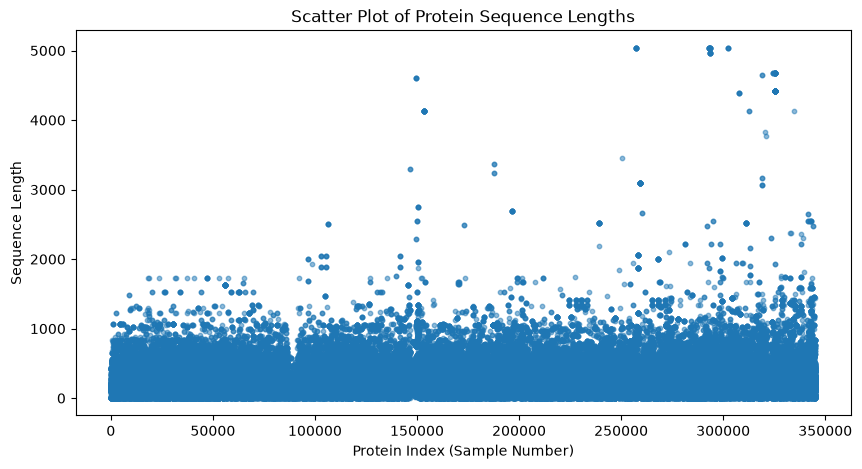

In [12]:
import matplotlib.pyplot as plt

# Reset index to get a continuous x-axis variable
df_clean = df[["seq_length"]].dropna().reset_index()

plt.figure(figsize=(10, 5))
# x = row index, y = sequence length
plt.scatter(df_clean.index, df_clean["seq_length"], alpha=0.5, s=10)

plt.xlabel("Protein Index (Sample Number)")
plt.ylabel("Sequence Length")
plt.title("Scatter Plot of Protein Sequence Lengths")
plt.show()


In [13]:
df = metadata.merge(
    df,
    how="inner",
    on="structureId"
)

In [14]:
df['classification'].value_counts()

classification
HYDROLASE                                   46336
TRANSFERASE                                 36424
OXIDOREDUCTASE                              34322
IMMUNE SYSTEM                               15615
LYASE                                       11682
                                            ...  
cell cycle/inhibitor                            1
Oxidoreductase, hydrolase                       1
OXIDOREDUCTASE(CHNH(D)-NAD+ OR NADP+(A))        1
ELECTRON TRANSPORT(IRON)                        1
antimicrobial                                   1
Name: count, Length: 4468, dtype: int64

In [15]:
df["classification"].isna().sum()

np.int64(1)

In [16]:
df = df.dropna(subset=["classification"]).copy()

In [17]:
def n_grams(sequence, n):
    return [sequence[i:i+n] for i in range(len(sequence)-n+1)]

In [18]:
df = df.dropna(subset=["sequence", "classification"]).copy()

In [19]:
df["sequence"] = df["sequence"].astype(str).str.upper().str.strip()

In [20]:
df["classification"].value_counts().head(20)

classification
HYDROLASE                                46336
TRANSFERASE                              36424
OXIDOREDUCTASE                           34321
IMMUNE SYSTEM                            15615
LYASE                                    11682
HYDROLASE/HYDROLASE INHIBITOR            11218
TRANSCRIPTION                             8919
VIRAL PROTEIN                             8495
TRANSPORT PROTEIN                         8371
VIRUS                                     6972
SIGNALING PROTEIN                         6469
ISOMERASE                                 6356
LIGASE                                    4964
MEMBRANE PROTEIN                          4891
PROTEIN BINDING                           4884
STRUCTURAL PROTEIN                        4335
CHAPERONE                                 4156
STRUCTURAL GENOMICS, UNKNOWN FUNCTION     3548
SUGAR BINDING PROTEIN                     3474
DNA BINDING PROTEIN                       3199
Name: count, dtype: int64

In [21]:
top20_classes = df["classification"].value_counts().head(20).index

In [22]:
df20 = df[df["classification"].isin(top20_classes)].copy()

In [23]:
X = df20["sequence"]
y = df20["classification"]

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 187703
Testing samples: 46926


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 3)
)

In [27]:
X_train_tfidf = vectorizer.fit_transform(X_train)

In [28]:
X_test_tfidf = vectorizer.transform(X_test)

In [29]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(187703, 8953)
(46926, 8953)


In [ ]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC(
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)
y_pred = svm_model.predict(X_test_tfidf)

In [ ]:
print(y_pred[:20])

In [31]:
print(y_test.iloc[:20].values)

<StringArray>
[            'TRANSPORT PROTEIN',              'MEMBRANE PROTEIN',
                 'IMMUNE SYSTEM',                     'HYDROLASE',
                   'TRANSFERASE',                'OXIDOREDUCTASE',
 'HYDROLASE/HYDROLASE INHIBITOR',                'OXIDOREDUCTASE',
 'HYDROLASE/HYDROLASE INHIBITOR',                     'HYDROLASE',
                     'HYDROLASE',             'TRANSPORT PROTEIN',
                 'TRANSCRIPTION',                     'HYDROLASE',
                   'TRANSFERASE',                     'HYDROLASE',
                   'TRANSFERASE',                'OXIDOREDUCTASE',
                   'TRANSFERASE',                         'LYASE']
Length: 20, dtype: str


In [32]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8568384264586796


In [33]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                                       precision    recall  f1-score   support

                            CHAPERONE       0.91      0.90      0.91       831
                  DNA BINDING PROTEIN       0.82      0.77      0.79       640
                            HYDROLASE       0.83      0.83      0.83      9267
        HYDROLASE/HYDROLASE INHIBITOR       0.76      0.77      0.76      2244
                        IMMUNE SYSTEM       0.91      0.92      0.91      3123
                            ISOMERASE       0.92      0.89      0.90      1271
                               LIGASE       0.89      0.85      0.87       993
                                LYASE       0.93      0.91      0.92      2336
                     MEMBRANE PROTEIN       0.80      0.73      0.77       978
                       OXIDOREDUCTASE       0.90      0.94      0.92      6864
                      PROTEIN BINDING       0.70      0.59      0.64       977
                    SIGNALING PROTEIN       0.74   

In [ ]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC(
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)


In [35]:
y_pred = svm_model.predict(X_test_tfidf)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                                       precision    recall  f1-score   support

                            CHAPERONE       0.91      0.90      0.91       831
                  DNA BINDING PROTEIN       0.82      0.77      0.79       640
                            HYDROLASE       0.83      0.83      0.83      9267
        HYDROLASE/HYDROLASE INHIBITOR       0.76      0.77      0.76      2244
                        IMMUNE SYSTEM       0.91      0.92      0.91      3123
                            ISOMERASE       0.92      0.89      0.90      1271
                               LIGASE       0.89      0.85      0.87       993
                                LYASE       0.93      0.91      0.92      2336
                     MEMBRANE PROTEIN       0.80      0.73      0.77       978
                       OXIDOREDUCTASE       0.90      0.94      0.92      6864
                      PROTEIN BINDING       0.70      0.59      0.64       977
                    SIGNALING PROTEIN       0.74   

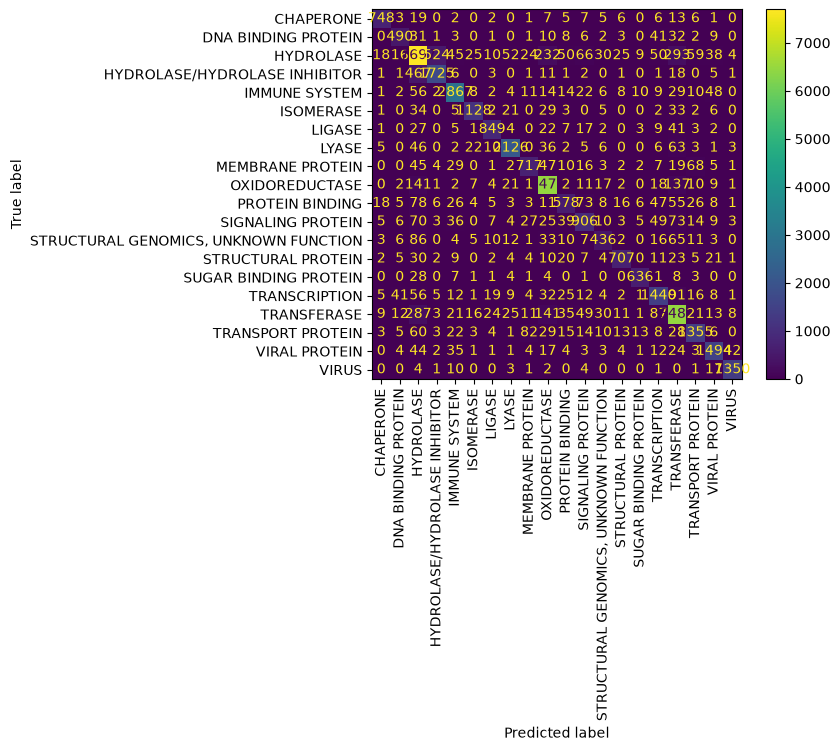

<Figure size 1200x1200 with 0 Axes>

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90
)

plt.figure(figsize=(12, 12))
plt.show()

In [1]:
results = []

results.append({
    "Model": "Linear SVM",
    "Features": "3-mer TF-IDF",
    "Accuracy": accuracy
})

pd.DataFrame(results)

NameError: name 'accuracy' is not defined

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

In [ ]:
rf_pred = rf_model.predict(X_test_tfidf)

In [26]:
from sklearn.model_selection import train_test_split

X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=30000,
    random_state=42,
    stratify=y_train
)

In [33]:
from sklearn.svm import LinearSVC
svm_small = LinearSVC(random_state=42)

svm_small.fit(
    X_train_small_tfidf,
    y_train_small
)
from sklearn.metrics import accuracy_score
svm_small_pred = svm_small.predict(X_test_small_tfidf)

svm_small_accuracy = accuracy_score(
    y_test,
    svm_small_pred
)

print("SVM accuracy on 30k:", svm_small_accuracy)

SVM accuracy on 30k: 0.7543579252440012


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
small_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 3)
)

X_train_small_tfidf = small_vectorizer.fit_transform(X_train_small)
X_test_small_tfidf = small_vectorizer.transform(X_test)

print(X_train_small_tfidf.shape)
print(X_test_small_tfidf.shape)

(30000, 8434)
(46926, 8434)


In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_small_tfidf,
    y_train_small
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [35]:
rf_pred = rf_model.predict(X_test_small_tfidf)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest accuracy:", rf_accuracy)

Random Forest accuracy: 0.7634786685419597
